# Notebook 10 – Target Variable Analysis

A target variable is the column in a dataset that we want a Machine Learning model to predict. It is also called the dependent variable, output variable, or label

For example, consider a customer dataset:

Age	MonthlyIncome	CustomerType	Purchased

 25	    20,000	      New	           No
 32	    35,000	     Returning	       Yes
 45	    50,000	     Returning         Yes
 22  	18,000	      New	           No
 38  	42,000	     Returning	       Yes

Here:

- Features (X): Age, Monthly Income, Customer Type
- Target (y): Purchased
- Goal: Predict whether a customer will purchase a product

Types of target variables

Type	                    Target example	                      ML task

Binary classification	   Purchased: Yes/No	       Predict one of two classes
Multiclass classification	Product category: A/B/C	   Predict one of several classes
Regression	                House price: ₹25,00,000	   Predict a numerical value

Important: We do not perform both classification and regression analysis on every dataset. Choose the analysis that matches your actual target variable.

In [3]:
import pandas as pd

df = pd.read_csv("target_variable_analysis.csv")

df.head()

,CustomerID,Age,MonthlyIncome,CustomerType,Purchased,HousePrice_Lakhs
0,1001,25,20000,New,No,20
1,1002,32,35000,Returning,Yes,25
2,1003,45,50000,Returning,Yes,30
3,1004,22,18000,New,No,22
4,1005,38,42000,Returning,Yes,35


In [4]:
target_col = "Purchased" #Identify the target variable

df[target_col].head()

0     No
1    Yes
2    Yes
3     No
4    Yes
Name: Purchased, dtype: str

### Class Distribution

Class distribution tells us how observations are divided among the different target categories.

In [ ]:
For example, suppose a customer dataset contains 1,000 observations:
    
Purchased	Number of customers

   Yes	         700
    No	         300
  Total      	1,000

This means 70% of customers purchased a product, while 30% did not

In [6]:
target_col = "Purchased"

class_distribution = df[target_col].value_counts()

print(class_distribution)

Purchased
Yes    11
No      9
Name: count, dtype: int64


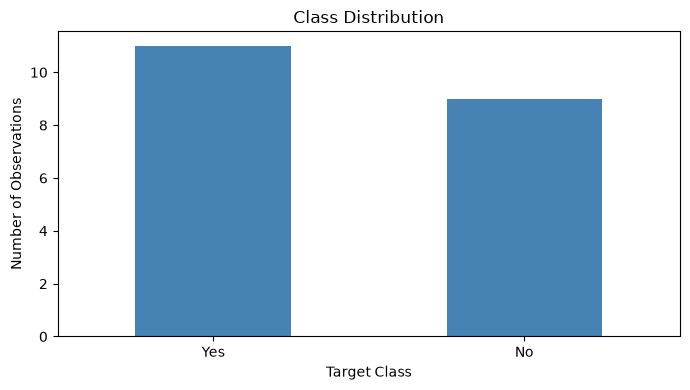

In [7]:
df[target_col].value_counts().plot(               #Visualize the class distribution
    kind="bar",
    figsize=(7, 4),
    color="steelblue"
)

plt.title("Class Distribution")
plt.xlabel("Target Class")
plt.ylabel("Number of Observations")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

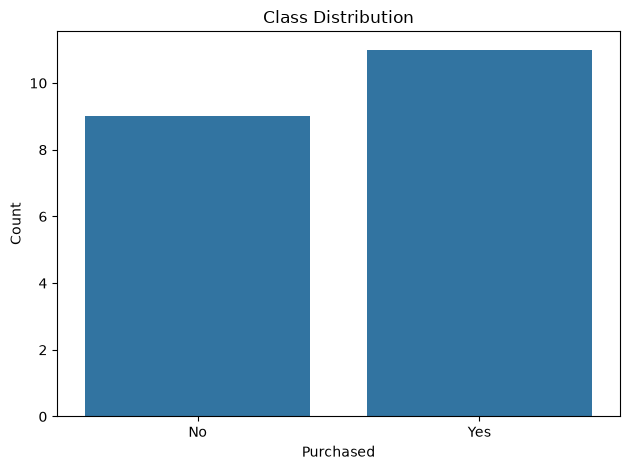

In [8]:
sns.countplot(data=df, x=target_col)       #count plot:

plt.title("Class Distribution")
plt.xlabel("Purchased")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

How to interpret the chart:

- Bars of similar heights indicate relatively balanced classes
- One very tall bar and one very short bar suggest class imbalance
- A class with very few observations may be difficult for a model to learn
Class distribution is the overall picture; class counts and percentages give us the exact numbers

## Class Counts

Class counts represent the number of observations belonging to each category

For example:

- Yes: 700 customers
- No: 300 customers



### Formula

$$
\text{Class Count}_i = \sum_{j=1}^{N} I(y_j = c_i)
$$


Where:

- \(N\) = total number of observations
- \(y_j\) = target value of observation \(j\)
- \(c_i\) = a particular class
- \(I(\cdot)\) = 1 when the condition is true and 0 otherwise

In [9]:
class_counts = df[target_col].value_counts()

print("Class Counts:")
print(class_counts)

print("\nTotal observations:", df[target_col].notna().sum())

Class Counts:
Purchased
Yes    11
No      9
Name: count, dtype: int64

Total observations: 20


In [10]:
class_counts = df[target_col].value_counts()        #Find the largest and smallest classes

print("Largest class:", class_counts.idxmax())
print("Largest class count:", class_counts.max())

print("Smallest class:", class_counts.idxmin())
print("Smallest class count:", class_counts.min())

Largest class: Yes
Largest class count: 11
Smallest class: No
Smallest class count: 9


Why class counts matter

- They reveal whether there is enough data for each class
- They help identify rare categories
- They help determine whether stratified train-test splitting is appropriate
- They help you decide whether class weighting or resampling might be necessary
  
Note that a small class is not automatically a problem; its importance depends on the task, available data, and evaluation requirements.

## Class Percentages

Class percentages show the proportion of observations belonging to each class, expressed as a percentage

Suppose the dataset contains 1,000 customers:

- 700 purchased the product
- 300 did not purchase the product
  
The percentages are 70% and 30%, respectively

 Formula

$$
\text{Class Percentage}_i =
\frac{\text{Class Count}_i}
{\text{Total Valid Target Observations}}
\times 100
$$

In [11]:
class_counts = df[target_col].value_counts()

class_percentages = (
    df[target_col].value_counts(normalize=True) * 100
)

print("Class Percentages:")
print(class_percentages.round(2))

Class Percentages:
Purchased
Yes    55.0
No     45.0
Name: proportion, dtype: float64


In [12]:
class_summary = pd.DataFrame({                     #Combine counts and percentages
    "Count": df[target_col].value_counts(),
    "Percentage": (
        df[target_col].value_counts(normalize=True) * 100
    )
})

class_summary["Percentage"] = class_summary["Percentage"].round(2)

print(class_summary)

           Count  Percentage
Purchased                   
Yes           11        55.0
No             9        45.0


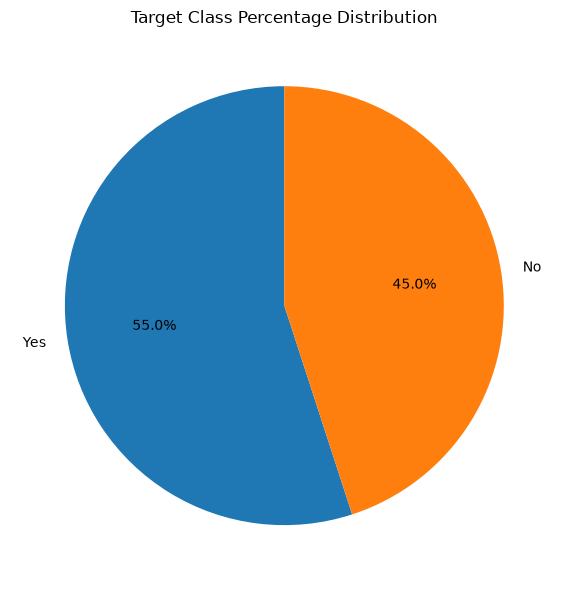

In [13]:
class_percentages = (                               #Visualize class percentages
    df[target_col].value_counts(normalize=True) * 100
)

class_percentages.plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90,
    figsize=(6, 6)
)

plt.title("Target Class Percentage Distribution")
plt.ylabel("")
plt.tight_layout()
plt.show()

A pie chart can work well for a small number of classes. For many classes, a bar chart is usually easier to read

Interpretation: If Yes accounts for 70% and No accounts for 30%, the target is not evenly distributed, but that alone does not establish that it is severely imbalanced

## Class Imbalance

Class imbalance occurs when some target classes have substantially more observations than others

Example:

     Class	Count	Percentage
     
   No fraud 9,900	  99%
   Fraud	100	       1%
   
    Total	10,000	 100%

This is a highly imbalanced dataset. The model sees many more examples of non-fraud than fraud

Why is class imbalance a problem?

Imagine a model that always predicts No fraud

Its accuracy would be:


$$
\text{Accuracy}
=
\frac{9900}{10000}\times100
=99\%
$$

Yet it would fail to detect every fraudulent transaction

This demonstrates why accuracy alone can be misleading when classes are imbalanced


Calculate the class imbalance ratio

A common descriptive measure is the ratio of the largest class count to the smallest class count.

Formula

$$
\text{Imbalance Ratio}
=
\frac{\text{Largest Class Count}}
{\text{Smallest Class Count}}
$$

For the fraud example:

$$
\text{Imbalance Ratio}
=
\frac{9900}{100}
=99
$$


The largest class is 99 times the size of the smallest class

In [14]:
class_counts = df[target_col].value_counts()           #

if len(class_counts) >= 2:
    imbalance_ratio = class_counts.max() / class_counts.min()

    print("Largest class:", class_counts.idxmax())
    print("Smallest class:", class_counts.idxmin())
    print("Imbalance ratio:", round(imbalance_ratio, 2))
else:
    print("At least two non-missing classes are required.")

Largest class: Yes
Smallest class: No
Imbalance ratio: 1.22


The imbalance ratio is descriptive, not a universal pass/fail threshold. Whether a ratio is concerning depends on the use case

## Target Distribution

Target distribution shows how the numerical target values are spread across the dataset

For example, a house-price dataset might contain values ranging from ₹10 lakh to ₹2 crore

The distribution helps us understand:

- Where most target values are concentrated
- Whether the target is symmetric or skewed
- Whether the target has a long tail
- Whether extreme values exist
- Whether a transformation may be useful

In [16]:
target_col = "HousePrice_Lakhs"

target = df[target_col].dropna()

print(target.describe())

count     20.000000
mean      42.400000
std       49.700577
min       20.000000
25%       24.750000
50%       29.500000
75%       38.500000
max      250.000000
Name: HousePrice_Lakhs, dtype: float64


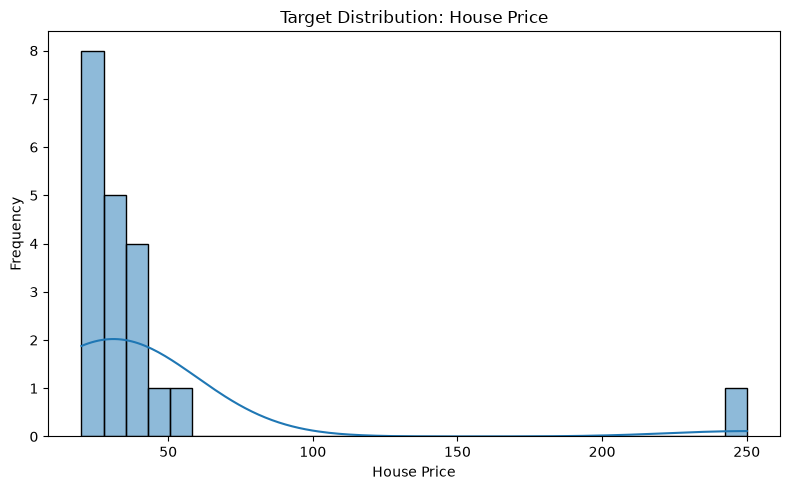

In [17]:
plt.figure(figsize=(8, 5))                  #Histogram

sns.histplot(target, bins=30, kde=True)

plt.title("Target Distribution: House Price")
plt.xlabel("House Price")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

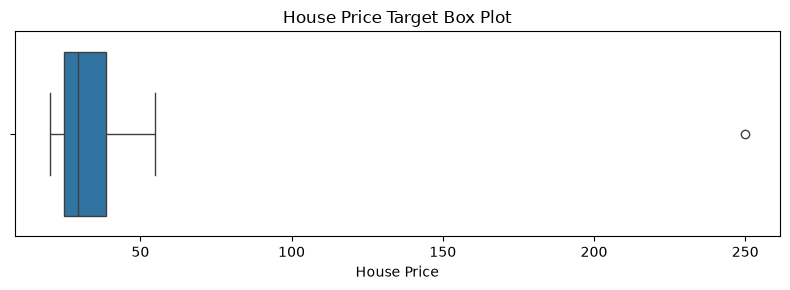

In [18]:
plt.figure(figsize=(8, 3))           #Boxplot

sns.boxplot(x=target)

plt.title("House Price Target Box Plot")
plt.xlabel("House Price")
plt.tight_layout()
plt.show()

How to interpret the distribution:

Approximately symmetric

Values are distributed relatively evenly around the center. Mean and median are often similar

Right-skewed

Most values are relatively low, with a long tail toward higher values. House prices often have this pattern

Left-skewed

Most values are relatively high, with a long tail toward lower values

A skewed target is not necessarily a bad target. Its shape helps you decide which models, metrics, and transformations to investigate


## Mean

The mean is the arithmetic average of all valid numerical target values

### Formula

$$
\mu = \frac{1}{N}\sum_{i=1}^{N} y_i
$$

Where:

- \(y_i\) = target value of observation \(i\)
- \(N\) = number of valid observations
- \(\mu\) = population mean, or the sample average when calculated from sample data


In [19]:
target_mean = target.mean()

print("Mean:", target_mean)

Mean: 42.4


Interpretation: The mean gives a useful measure of the average target value. However, unusually high or low values can pull the mean away from the center of most observations

## Median

The median is the middle value when observations are arranged in ascending order

For an even number of observations, it is the average of the two middle values


For odd $N$:

$$
\text{Median} = y_{\left(\frac{N+1}{2}\right)}
$$

For even $N$:

$$
\text{Median} =
\frac{y_{\left(\frac{N}{2}\right)} + y_{\left(\frac{N}{2}+1\right)}}{2}
$$

In [20]:
target_median = target.median()

print("Median:", target_median)

Median: 29.5


In [21]:
print("Mean:", target.mean())                   #Compare mean and median
print("Median:", target.median())

Mean: 42.4
Median: 29.5


Interpretation:

- Mean approximately equal to median: the distribution may be relatively symmetric
- Mean greater than median: the distribution may be right-skewed
- Mean less than median: the distribution may be left-skewed
  
These are useful clues, not definitive proof of the distribution's shape

## Variance


Variance measures how far target values spread around their mean, using squared deviations.

 Population Variance

$$
\sigma^2 = \frac{1}{N}\sum_{i=1}^{N}(y_i-\mu)^2
$$

 Sample Variance

$$
s^2 = \frac{1}{n-1}\sum_{i=1}^{n}(y_i-\bar{y})^2
$$

Use population variance when the observations represent the entire population of interest. Use sample variance when estimating population variance from a sample

In [22]:
population_variance = target.var(ddof=0)
sample_variance = target.var(ddof=1)

print("Population Variance:", population_variance)
print("Sample Variance:", sample_variance)

Population Variance: 2346.64
Sample Variance: 2470.1473684210523


In Pandas:

- ddof=0 calculates population variance
- ddof=1 calculates sample variance and is the default
- 
Interpretation: A higher variance indicates greater dispersion in the target values. Variance is measured in squared units, so for house prices measured in rupees, its unit is rupees squared

## Standard Deviation

Standard deviation measures the spread of values around their mean, in the same units as the target

Formula

$$
\sigma = \sqrt{\frac{1}{N}\sum_{i=1}^{N}(y_i-\mu)^2}
$$

For a sample, use:

$$
s = \sqrt{s^2}
$$

In [23]:
population_std = target.std(ddof=0)
sample_std = target.std(ddof=1)

print("Population Standard Deviation:", population_std)
print("Sample Standard Deviation:", sample_std)

Population Standard Deviation: 48.442130423836645
Sample Standard Deviation: 49.700577143742024


Why standard deviation matters

Suppose two datasets have the same mean house price of ₹30 lakh:
- Dataset A: prices are concentrated around ₹30 lakh.
- Dataset B: prices vary substantially, from very inexpensive to very expensive
  
Dataset B will have a larger standard deviation.

A large standard deviation does not necessarily mean the model will perform poorly. It indicates that the target values vary widely, which may make accurate prediction more challenging.

## Skewness

Skewness measures the asymmetry of a distribution

The population standardized third central moment is:


Skewness Formula

$$
\gamma_1 = \frac{E[(Y-\mu)^3]}{\sigma^3}
$$

For a sample, Pandas provides a sample skewness estimate using Series.skew().

Interpretation

Skewness	Typical interpretation

Near 0	       Approximately symmetric
Positive	  Right-skewed
Negative	  Left-skewed

The exact interpretation depends on the data; skewness near zero does not guarantee a normal distribution

In [24]:
target_skewness = target.skew()

print("Target Skewness:", target_skewness)

Target Skewness: 4.231606090110492


Example

If house prices have a skewness of 2.1, the target is positively skewed. A small number of expensive houses may extend the right tail

Possible next steps include:

- Inspecting extreme values
- Checking whether the expensive houses are valid
- Considering a logarithmic transformation if appropriate
- Comparing model performance with and without a transformation

## Outliers

A target outlier is an observation whose target value is unusually far from the rest of the target values

For example, house prices might be:
\[
20, 22, 24, 25, 27,30, 250
\]

The ₹250 lakh observation is much larger than the other values. It may be a genuine luxury house, a data-entry error, or a different type of property.

We should investigate rather than immediately delete it.

Method 1: IQR method

The interquartile range is the difference between the third quartile and the first quartile

$$
IQR = Q_3 - Q_1
$$



$$
L = Q_1 - 1.5(IQR)
$$

Lower and upper fences are:

$$
U = Q_3 + 1.5(IQR)
$$

Values below \(L\) or above \(U\) are flagged as potential outliers.

In [25]:
Q1 = target.quantile(0.25)
Q3 = target.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = target[
    (target < lower_bound) |
    (target > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

print("\nNumber of potential outliers:", len(outliers))
print(outliers)

Q1: 24.75
Q3: 38.5
IQR: 13.75
Lower Bound: 4.125
Upper Bound: 59.125

Number of potential outliers: 1
16    250
Name: HousePrice_Lakhs, dtype: int64


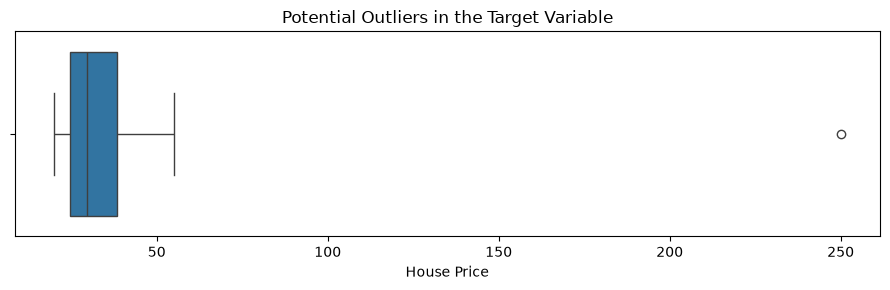

In [26]:
plt.figure(figsize=(9, 3))             #Visualize target outliers

sns.boxplot(x=target)

plt.title("Potential Outliers in the Target Variable")
plt.xlabel("House Price")
plt.tight_layout()
plt.show()


Method 2: Z-score

The Z-score describes how many standard deviations a value is from the mean


 Z-Score Formula

$$
z_i = \frac{y_i - \bar{y}}{s}
$$

A common screening rule flags values with an absolute Z-score greater than 3

In [27]:
target_std = target.std(ddof=0)

if target_std > 0:
    z_scores = (target - target.mean()) / target_std

    z_outliers = target[z_scores.abs() > 3]

    print("Potential Z-score outliers:")
    print(z_outliers)
else:
    print("Z-scores are undefined because the target has zero variance.")

Potential Z-score outliers:
16    250
Name: HousePrice_Lakhs, dtype: int64


The Z-score method can be less effective for strongly skewed distributions because the mean and standard deviation are sensitive to extreme values

The IQR method is often a useful alternative

How should we handle target outliers?

1. Genuine observation: Keep it if it represents a valid case relevant to the task
2. Data-entry error: Correct it using a reliable source or exclude it when correction is impossible and exclusion is justified
3. Different population: Investigate whether it belongs to a distinct group or requires a separate modeling approach
4. Extreme but important case: Consider robust metrics, suitable models, or transformations

Removing valid target extremes can teach the model to ignore precisely the cases it needs to predict

Why is target variable analysis important before Machine Learning?

Target analysis helps you make informed decisions before training a model

1. Select the correct ML algorithm

A categorical target generally calls for a classification approach, whereas a continuous numerical target generally calls for regression

2. Identify class imbalance

Class counts help you decide whether class weights, resampling, stratified splitting, or alternative evaluation metrics are worth considering

3. Understand the target's statistical properties

Mean, median, spread, skewness, and distribution plots reveal the characteristics of a numerical prediction problem

4. Detect data-quality problems

Missing target values, invalid labels, incorrect measurements, and extreme observations can affect training and evaluation

5. Choose appropriate evaluation metrics

Classification may require precision, recall, F1-score, or PR-AUC. Regression may use MAE, RMSE, or \(R^2\), depending on the problem

6. Make preprocessing decisions

Target skewness may motivate testing a transformation. However, target transformations, feature preprocessing, and resampling must be applied without leaking information from validation or test data